# Сравнение рекомендательных моделей

Слободин Дмитрий Сергеевич

В работе сравниваются Item-based CF, iALS, EASE, FM с метаданными и iALS с изменённым таргетом.
Данные — Amazon Reviews 2014, Video Games, 5-core. Задача — составить для пользователя
список из десяти товаров, которые он ещё не оценивал. Релевантными считаются товары
с будущей оценкой 4 или 5. В категорию входят игры, приставки и аксессуары.

## Запуск

Нужен Python 3.13. Команды выполняются из корня репозитория:

```powershell
python -m pip install -r requirements.txt
python run_experiments.py
python -m jupyterlab experiments.ipynb
```

При первом запуске загружаются отзывы и метаданные. Можно также выполнить все ячейки
в Jupyter с тем же окружением. Результаты сохраняются в `results/` и используются повторно,
если код, сетки параметров и данные не менялись. Для повторного обучения:
`python run_experiments.py --force`. Исходные данные хранятся локально и исключены из Git.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from data_utils import ROOT, URLS, prepare_data
from run_experiments import GRIDS, run_validation, run_final

np.random.seed(42)
pd.set_option('display.max_colwidth', 140)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Данные

[Описание датасета](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html).
[Файлы на сервере авторов](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/).

Использованы `reviews_Video_Games_5.json.gz` и `meta_Video_Games.json.gz`.
Архивы читаются построчно. Записи, не соответствующие JSON, разбираются через `ast.literal_eval`.

| Поле | Содержание |
|---|---|
| reviewerID | ID пользователя |
| asin | ID товара, общий ключ отзывов и метаданных |
| overall | оценка от 1 до 5 |
| unixReviewTime | время отзыва, с точностью до дня |
| title | название товара |
| brand | бренд |
| categories | категории товара |

В FM использованы бренд и категории. Они считаются постоянными свойствами товара,
доступными до рекомендации. Исторических версий этих полей нет, поэтому это допущение.
Текст отзыва, голоса о полезности, цена, salesRank и related в признаки не входят.

In [2]:
bundle = prepare_data()
audit = bundle['audit']
display(pd.Series({k: audit[k] for k in ['raw_interactions', 'clean_interactions', 'users', 'items', 'sparsity']}))
display(pd.DataFrame({'url': URLS, 'sha256': audit['sha256']}))
display(bundle['clean'].head())

raw_interactions      231780.000000
clean_interactions    231780.000000
users                  24303.000000
items                  10672.000000
sparsity                   0.999106
dtype: float64

,url,sha256
reviews_Video_Games_5.json.gz,https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/reviews_Video_Games_5.json.gz,db2a33eba13cc437077e2c1f98cccf656922bf28203585d561c48fb1048184ea
meta_Video_Games.json.gz,https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/meta_Video_Games.json.gz,09457ba57ad086160de4a632e3d9b160fba625239eee31828f39c2dd520da395


,user_id,item_id,rating,timestamp
0,A2AXQTB83VMK4L,B0000296O5,5.0,939859200
1,A1QA8K3LD9K892,B00000K1V2,2.0,942192000
2,A3VWWQT4XDSBGQ,B00000K4AX,5.0,942192000
3,AMGJMFJ63DWWH,B00000JL6V,4.0,942192000
4,AMGJMFJ63DWWH,B00001NFUA,5.0,942192000


## 2. Подготовка и EDA

Проверены пропуски в обязательных полях, диапазон оценок, временные метки и повторные
пары пользователь–товар. При повторе сохраняется первый отзыв по времени.

Использована вся опубликованная подвыборка 5-core, без дополнительного случайного отбора.
После очистки проверяются ограничения задания: 100 тыс. — 2 млн взаимодействий,
не менее 1000 пользователей и 1000 товаров.

Сам 5-core сформирован авторами по полной истории: у каждого пользователя и товара
не менее пяти отзывов. Поэтому данные смещены в сторону активных пользователей
и популярных товаров. Дополнительного отбора по будущей активности нет.

user_id      0
item_id      0
rating       0
timestamp    0
Name: missing_required_fields, dtype: int64

invalid_or_missing_removed    0
duplicate_pairs_removed       0
dtype: int64

,user_activity,item_popularity
count,24303.000000,10672.000000
mean,9.537094,21.718516
std,12.789697,34.068551
min,5.000000,5.000000
25%,5.000000,7.000000
50%,7.000000,11.000000
75%,10.000000,22.000000
max,773.000000,802.000000


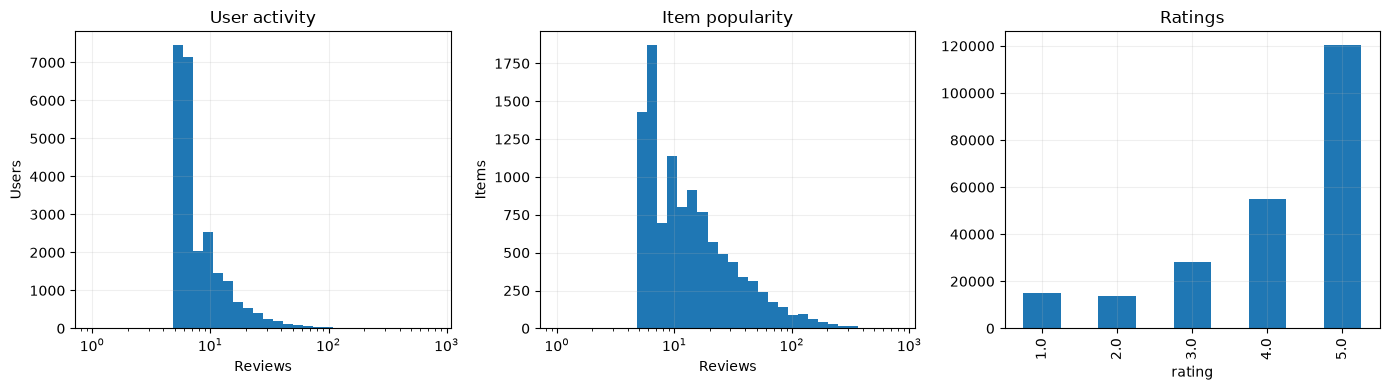

catalog_items          10093
matched                10093
with_title               253
with_brand               149
with_categories        10013
distinct_categories      196
Name: metadata_coverage, dtype: int64

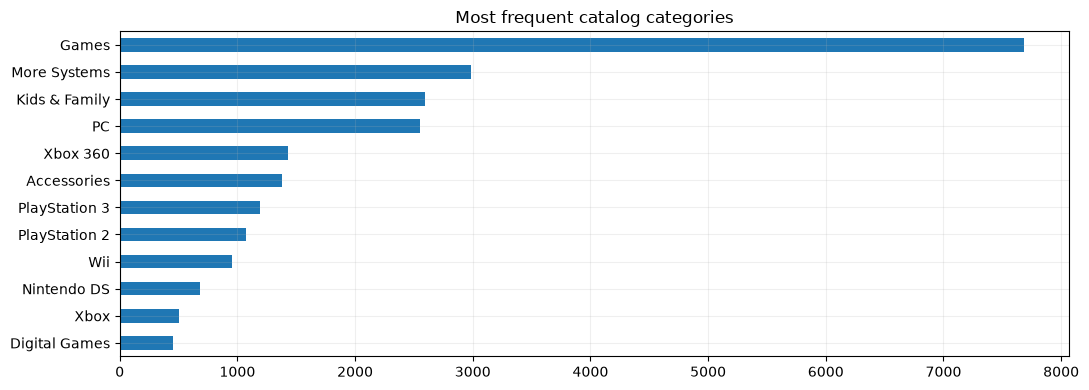

In [3]:
display(pd.Series(audit['missing'], name='missing_required_fields'))
display(pd.Series({k: audit[k] for k in ['invalid_or_missing_removed', 'duplicate_pairs_removed']}))
clean = bundle['clean']
activity = clean.groupby('user_id').size()
popularity = clean.groupby('item_id').size()
display(pd.DataFrame({'user_activity': activity.describe(), 'item_popularity': popularity.describe()}))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(activity, bins=np.geomspace(1, activity.max() + 1, 35)); axes[0].set_xscale('log')
axes[0].set(title='User activity', xlabel='Reviews', ylabel='Users')
axes[1].hist(popularity, bins=np.geomspace(1, popularity.max() + 1, 35)); axes[1].set_xscale('log')
axes[1].set(title='Item popularity', xlabel='Reviews', ylabel='Items')
clean.rating.value_counts().sort_index().plot.bar(ax=axes[2], title='Ratings')
plt.tight_layout(); plt.show()
display(pd.Series(audit['metadata'], name='metadata_coverage'))
cats = pd.Series([c for m in bundle['metadata'] for c in m['categories']]).value_counts()
cats.head(12).sort_values().plot.barh(title='Most frequent catalog categories')
plt.tight_layout(); plt.show()

### 2.1. Разреженность и признаки товаров

Выбор одной категории уменьшает каталог, но не гарантирует плотные пользовательские истории.
Ниже приведены заполненность матрицы и доли товаров с метаданными.
Все расчёты выполнены на той же выборке, что используется в эксперименте.

In [4]:
dataset_summary = pd.Series({
    'Отзывы': len(clean),
    'Пользователи': clean.user_id.nunique(),
    'Товары': clean.item_id.nunique(),
    'Отзывов на пользователя, среднее': len(clean) / clean.user_id.nunique(),
    'Заполненность матрицы, %': 100 * len(clean) / (clean.user_id.nunique() * clean.item_id.nunique()),
}, name='Значение')
display(dataset_summary.to_frame())
coverage = pd.DataFrame({
    'Поле': ['Категории', 'Бренд', 'Название'],
    'Заполнено товаров': [audit['metadata']['with_categories'], audit['metadata']['with_brand'],
                          audit['metadata']['with_title']],
})
coverage['Доля train-каталога, %'] = 100 * coverage['Заполнено товаров'] / audit['train_items']
display(coverage)

,Значение
Отзывы,231780.000000
Пользователи,24303.000000
Товары,10672.000000
"Отзывов на пользователя, среднее",9.537094
"Заполненность матрицы, %",0.089366


,Поле,Заполнено товаров,"Доля train-каталога, %"
0,Категории,10013,99.207371
1,Бренд,149,1.476271
2,Название,253,2.506688


Матрица заполнена примерно на 0,089%; в полной истории в среднем 9,54 отзыва на пользователя.
В Video Games входят игры для разных платформ, приставки и аксессуары.
Категории есть у 99,2% train-каталога, бренд — у 1,5%. Поэтому метаданные FM в основном
описывают категории товаров. Эти числа характеризуют объём доступных признаков,
но сами по себе не объясняют разницу качества моделей.

## 3. Разбиение и метрики

Данные разделены по времени для всего датасета. Границы — 80-й и 90-й процентили
времени отзывов. Train содержит события до первой границы, validation — от первой
до второй, test — начиная со второй. День на границе целиком относится к следующей части,
поэтому доли немного отличаются от 80/10/10.

Словари пользователей и товаров построены по train. В оценку входят пользователи
с минимум тремя отзывами в train и хотя бы одним релевантным товаром в проверяемой части.
Новые пользователи и товары исключены; их количество приведено в таблице.
У validation и test могут быть разные пользователи, но для всех моделей внутри одной
части набор пользователей одинаков.

Каждая модель ранжирует весь train-каталог. Из кандидатов исключаются все известные
пользователю товары, в том числе с низкими оценками. На validation известна история train,
на test — train+validation. Равные оценки упорядочиваются по индексу товара.
Случайная выборка негативов при оценке не используется.

Параметры выбираются по NDCG@10 на validation. Затем модели заново обучаются
на train+validation и проверяются на test с фиксированным train-каталогом.
Релевантность для всех моделей: оценка 4–5.

### Обозначения

$R_u$ — множество релевантных кандидатов пользователя $u$; $i_{u,j}$ — товар
на позиции $j$ в рекомендациях. Индикатор попадания:

$$
\ell_{u,j}=\mathbf{1}\!\left[i_{u,j}\in R_u\right].
$$

### NDCG@10

Учитывает позиции релевантных товаров. Попадание в начале списка даёт больший вклад.

$$
\operatorname{DCG}@10(u)
=\sum_{j=1}^{10}\frac{\ell_{u,j}}{\log_2(j+1)}.
$$

$$
\operatorname{IDCG}@10(u)
=\sum_{j=1}^{\min(10,\lvert R_u\rvert)}\frac{1}{\log_2(j+1)}.
$$

$$
\operatorname{NDCG}@10(u)
=\frac{\operatorname{DCG}@10(u)}{\operatorname{IDCG}@10(u)}.
$$

### MAP@10

Сначала считается точность на каждой позиции, затем усредняется точность в позициях попаданий.

$$
P_u(j)=\frac{1}{j}\sum_{a=1}^{j}\ell_{u,a}.
$$

$$
\operatorname{AP}@10(u)
=\frac{\sum_{j=1}^{10}P_u(j)\,\ell_{u,j}}{\min(10,\lvert R_u\rvert)}.
$$

Здесь используется нормировка на минимум из 10 и числа релевантных кандидатов.
Это выбранный вариант AP@10; в других определениях делителем может быть число
всех релевантных объектов.

$$
\operatorname{MAP}@10
=\frac{1}{\lvert U_{\mathrm{eval}}\rvert}
\sum_{u\in U_{\mathrm{eval}}}\operatorname{AP}@10(u).
$$

### Recall@10

Показывает долю релевантных товаров, найденных в первых десяти рекомендациях.

$$
\operatorname{Recall}@10(u)
=\frac{\sum_{j=1}^{10}\ell_{u,j}}{\lvert R_u\rvert}.
$$

$U_{\mathrm{eval}}$ — общий набор оцениваемых пользователей. NDCG@10 и Recall@10
также усредняются по этому набору. Пользователи без релевантных кандидатов
не входят в среднее. Реализация находится в `evaluation.py`.

In [5]:
display(pd.DataFrame(audit['periods']).T)
print('Границы UTC:', audit['split_boundaries'])
print('Train users/items:', audit['train_users'], audit['train_items'])
print('Пользователей с >=3 train-событиями:', audit['eligible_history_users'])
assert bundle['train'].timestamp.max() < bundle['validation'].timestamp.min()
assert bundle['validation'].timestamp.max() < bundle['test'].timestamp.min()

,raw_events,warm_events,cold_events_excluded,relevant_warm_events,start,end,evaluated_users
train,185349,185349,0,138586,1999-10-14T00:00:00+00:00,2013-08-21T00:00:00+00:00,NaN
validation,23133,10568,12565,8429,2013-08-22T00:00:00+00:00,2014-01-17T00:00:00+00:00,3007
test,23298,8596,14702,6626,2014-01-18T00:00:00+00:00,2014-07-22T00:00:00+00:00,2224


Границы UTC: ['2013-08-22T00:00:00+00:00', '2014-01-18T00:00:00+00:00']
Train users/items: 22209 10093
Пользователей с >=3 train-событиями: 20522


### 3.1. Истории пользователей в оценке

Общее распределение активности включает пользователей, которые не попали в итоговые метрики.
Поэтому длина истории и число релевантных кандидатов дополнительно считаются для каждого
оцениваемого набора. На validation доступна история train, на test — train+validation
в пределах фиксированных словарей. Использованы те же правила отбора, что в `evaluate`.

Часть,validation,test
Пользователи,3007.000,2224.000
"История, медиана",5.000,6.000
"История, среднее",9.950,11.338
"История до 5 отзывов, %",51.945,44.739
"Релевантных товаров, среднее",1.890,1.976
"Один релевантный товар, %",61.723,60.656
"Кандидатов, среднее",10083.050,10081.662


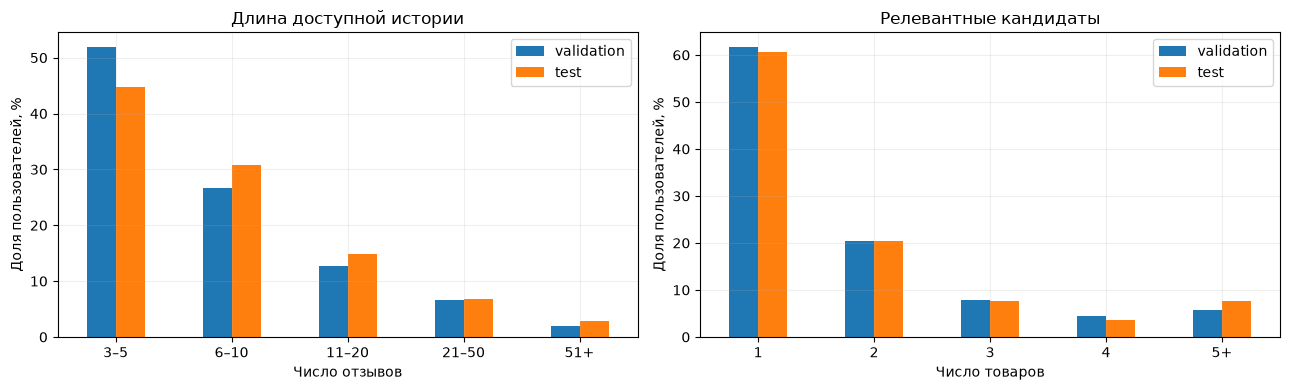

In [6]:
from data_utils import make_matrix
from evaluation import evaluate

train_frame = bundle['train']
final_frame = pd.concat([bundle['train'], bundle['validation']], ignore_index=True)
eligible = set(bundle['eligible_users'].tolist())
cohorts = {}
summary_rows = []
for period, history_frame in [('validation', train_frame), ('test', final_frame)]:
    known = history_frame.groupby('user_idx').item_idx.apply(set).to_dict()
    positives = bundle[period].loc[bundle[period].rating >= 4].groupby('user_idx').item_idx.apply(set)
    relevant_counts = {
        int(u): len(items - known.get(u, set()))
        for u, items in positives.items()
        if u in eligible and items - known.get(u, set())
    }
    user_ids = sorted(relevant_counts)
    history_lengths = history_frame.groupby('user_idx').size().reindex(user_ids)
    relevant_lengths = pd.Series(relevant_counts).reindex(user_ids)
    candidate_counts = bundle['shape'][1] - history_lengths
    cohorts[period] = pd.DataFrame({
        'history': history_lengths,
        'relevant': relevant_lengths,
        'candidates': candidate_counts,
    })
    summary_rows.append({
        'Часть': period,
        'Пользователи': len(user_ids),
        'История, медиана': history_lengths.median(),
        'История, среднее': history_lengths.mean(),
        'История до 5 отзывов, %': 100 * (history_lengths <= 5).mean(),
        'Релевантных товаров, среднее': relevant_lengths.mean(),
        'Один релевантный товар, %': 100 * (relevant_lengths == 1).mean(),
        'Кандидатов, среднее': candidate_counts.mean(),
    })
cohort_summary = pd.DataFrame(summary_rows).set_index('Часть')
display(cohort_summary.T.round(3))

history_labels = ['3–5', '6–10', '11–20', '21–50', '51+']
relevance_labels = ['1', '2', '3', '4', '5+']
history_distribution = {}
relevance_distribution = {}
for period, cohort in cohorts.items():
    history_groups = pd.cut(cohort.history, [2, 5, 10, 20, 50, np.inf], labels=history_labels)
    relevance_groups = pd.cut(cohort.relevant, [0, 1, 2, 3, 4, np.inf], labels=relevance_labels)
    history_distribution[period] = 100 * history_groups.value_counts(normalize=True).reindex(history_labels)
    relevance_distribution[period] = 100 * relevance_groups.value_counts(normalize=True).reindex(relevance_labels)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.DataFrame(history_distribution).plot.bar(ax=axes[0], rot=0)
pd.DataFrame(relevance_distribution).plot.bar(ax=axes[1], rot=0)
axes[0].set(title='Длина доступной истории', xlabel='Число отзывов', ylabel='Доля пользователей, %')
axes[1].set(title='Релевантные кандидаты', xlabel='Число товаров', ylabel='Доля пользователей, %')
plt.tight_layout(); plt.show()

У test-пользователя медианная доступная история — 6 отзывов; у 44,7% пользователей
не больше пяти. После исключения известных товаров остаётся в среднем около
10 082 кандидатов. Таким образом, модели ранжируют большой каталог по короткой истории.

У 60,7% test-пользователей зафиксирован ровно один релевантный товар. Другие подходящие
товары без отзыва попаданиями не считаются. Это ограничение наблюдаемой релевантности.
При этом один релевантный товар не ограничивает максимум NDCG: если поставить его первым,
пользовательский NDCG равен 1.

Эти особенности согласуются с невысокими метриками, но не доказывают причину отставания
одной модели от другой.

### 3.2. Какие события исключены

Термин «новый» ниже означает отсутствие ID в первоначальном train. Исключённые события
не входят в релевантные множества и знаменатели метрик. Пользователь без оставшихся
релевантных товаров не входит в среднее. Поэтому оценка относится к выбранной известной
части данных, а не ко всему потоку отзывов.

In [7]:
t1, t2 = [int(pd.Timestamp(value).timestamp()) for value in audit['split_boundaries']]
raw_validation = clean[(clean.timestamp >= t1) & (clean.timestamp < t2)]
raw_test = clean[clean.timestamp >= t2]
train_user_ids = set(train_frame.user_id)
train_item_ids = set(train_frame.item_id)
excluded_rows = []
for period, frame in [('validation', raw_validation), ('test', raw_test)]:
    new_user = ~frame.user_id.isin(train_user_ids)
    new_item = ~frame.item_id.isin(train_item_ids)
    excluded_rows.append({
        'Часть': period,
        'Пользователь и товар известны': int((~new_user & ~new_item).sum()),
        'Новый пользователь': int((new_user & ~new_item).sum()),
        'Новый товар': int((~new_user & new_item).sum()),
        'Оба новые': int((new_user & new_item).sum()),
        'Исключено, %': 100 * (new_user | new_item).mean(),
    })
display(pd.DataFrame(excluded_rows).set_index('Часть').round(3))

available_before_test = pd.concat([train_frame[['user_id', 'item_id']],
                                 raw_validation[['user_id', 'item_id']]], ignore_index=True)
known_by_test = (raw_test.user_id.isin(set(available_before_test.user_id))
                 & raw_test.item_id.isin(set(available_before_test.item_id)))
known_in_frozen_catalog = (raw_test.user_id.isin(train_user_ids)
                           & raw_test.item_id.isin(train_item_ids))
excluded_but_known_by_test = int((known_by_test & ~known_in_frozen_catalog).sum())
print('Исключены фиксированными словарями, хотя уже встречались до test:', excluded_but_known_by_test)

,Пользователь и товар известны,Новый пользователь,Новый товар,Оба новые,"Исключено, %"
Часть,,,,,
validation,10568,5140,5971,1454,54.316
test,8596,6454,5807,2441,63.104


Исключены фиксированными словарями, хотя уже встречались до test: 5151


Из исходного test исключено 63,1% событий. Для 5 151 из них пользователь и товар уже
встречались к концу validation. Они исключены потому, что словари зафиксированы
по первоначальному train, хотя финальные модели обучаются на train+validation.
Расширение словарей перед test позволило бы учесть часть этих событий после остальных
ограничений по активности и релевантности. Это отдельный вариант протокола;
в текущих результатах словари и набор оцениваемых пользователей сохранены.

## 4. Модели

### Обозначения

$H\in\{0,1\}^{m\times n}$ — матрица взаимодействий обучающей части:
$H_{ui}=1$, если пользователь $u$ оставил отзыв о товаре $i$, иначе $H_{ui}=0$.
Здесь $m$ — число пользователей, $n$ — число товаров. Для базовых моделей
учитывается факт отзыва независимо от выставленной оценки.

### Item-based CF

Сходство товаров считается по косинусу столбцов матрицы взаимодействий:

$$
s_{ij}=\frac{H_{:i}^{\mathsf T}H_{:j}}
{\lVert H_{:i}\rVert_2\,\lVert H_{:j}\rVert_2}.
$$

Величина $n_{ij}$ — число пользователей, взаимодействовавших с обоими товарами.
При сглаживании сходство заменяется на:

$$
n_{ij}=\sum_{u=1}^{m}H_{ui}H_{uj},
\qquad
\widetilde{s}_{ij}=s_{ij}\frac{n_{ij}}{n_{ij}+\gamma}.
$$

Параметр $\gamma$ соответствует `shrinkage`. Без сглаживания используется исходное сходство.
Диагональ обнуляется. В каждой строке остаются $L$ ближайших соседей исходного товара;
параметр $L$ соответствует `neighbors`. После усечения матрица $S$ может быть несимметричной.

Оценки кандидатов для пользователя:

$$
\widehat{\boldsymbol r}_u=H_{u:}S.
$$

Отдельной функции потерь нет. [Sarwar et al.](https://www.ra.ethz.ch/CDstore/www10/papers/519/)

### iALS

$\boldsymbol x_u,\boldsymbol y_i\in\mathbb{R}^{f}$ — факторы пользователя и товара,
$X\in\mathbb{R}^{m\times f}$ и $Y\in\mathbb{R}^{n\times f}$ — матрицы факторов.
Прогноз — их скалярное произведение:

$$
\widehat r_{ui}=\boldsymbol x_u^{\mathsf T}\boldsymbol y_i.
$$

Бинарный таргет и уверенность задаются так:

$$
p_{ui}=H_{ui},
\qquad c_{ui}=1+\alpha H_{ui}.
$$

В эксперименте $\alpha=20$: вес наблюдаемой пары равен 21, неизвестной — 1.
Минимизируется взвешенная квадратичная ошибка с L2-регуляризацией:

$$
\mathcal{L}(X,Y)
=\sum_{u=1}^{m}\sum_{i=1}^{n}
c_{ui}\left(p_{ui}-\boldsymbol x_u^{\mathsf T}\boldsymbol y_i\right)^2
+\lambda\left(\lVert X\rVert_F^2+\lVert Y\rVert_F^2\right).
$$

Факторы пользователей и товаров обновляются поочерёдно. При фиксированных $Y$
обновление пользователя получается из системы:

$$
\left(
Y^{\mathsf T}Y
+\alpha\sum_{i\in I_u}\boldsymbol y_i\boldsymbol y_i^{\mathsf T}
+\lambda I_f
\right)\boldsymbol x_u
=(1+\alpha)\sum_{i\in I_u}p_{ui}\boldsymbol y_i.
$$

$I_u$ — товары из обучающей истории пользователя, $I_f$ — единичная матрица размера $f$.
Для товаров решается аналогичная система. Вклад неизвестных пар считается через
матрицу Грама, без перебора всех пар. [Hu, Koren, Volinsky](https://yifanhu.net/PUB/cf.pdf)

### EASE

Матрица весов $B\in\mathbb{R}^{n\times n}$ восстанавливает историю пользователя:

$$
\min_{B:\,\operatorname{diag}(B)=\boldsymbol 0}
\quad \lVert H-HB\rVert_F^2+\lambda\lVert B\rVert_F^2.
$$

Решение:

$$
P=\left(H^{\mathsf T}H+\lambda I_n\right)^{-1}.
$$

$$
B_{ij}=-\frac{P_{ij}}{P_{jj}}\quad(i\ne j),
\qquad B_{jj}=0.
$$

Деление выполняется по столбцам: весь столбец $j$ делится на $-P_{jj}$.
Оценки рекомендаций:

$$
\widehat{\boldsymbol r}_u=H_{u:}B.
$$

В коде решение вычисляется через разложение Холецкого.
Память растёт квадратично с числом товаров. [Steck](https://arxiv.org/abs/1905.03375)

### FM

Признаки пары: ID пользователя, ID товара, бренд и категории товара.
Вектор $\boldsymbol z\in\{0,1\}^{d}$ указывает активные признаки.
Повторные признаки удалены, отсутствующие метаданные имеют отдельный индекс.
Нулевой индекс используется для дополнения строк и не даёт вклада в прогноз.

Модель второго порядка:

$$
f(\boldsymbol z)=w_0+\sum_{j=1}^{d}w_jz_j
+\sum_{j=1}^{d}\sum_{k=j+1}^{d}
\left\langle\boldsymbol v_j,\boldsymbol v_k\right\rangle z_jz_k.
$$

Попарные взаимодействия в коде вычисляются без перебора пар:

$$
\sum_{j<k}\left\langle\boldsymbol v_j,\boldsymbol v_k\right\rangle z_jz_k
=\frac12\sum_{a=1}^{f}
\left[
\left(\sum_{j=1}^{d}v_{ja}z_j\right)^2
-\sum_{j=1}^{d}v_{ja}^{2}z_j^{2}
\right].
$$

Положительный пример — любой отзыв из train. На него выбираются четыре неизвестные
пары того же пользователя. Для примера $b$ метка $y_b$ равна 1 у наблюдаемой пары
и 0 у выбранной неизвестной. Функция потерь на батче $\mathcal B$:

$$
\mathcal{L}_{\mathrm{BCE}}
=\frac{1}{\lvert\mathcal B\rvert}
\sum_{b\in\mathcal B}
\left[\log\left(1+\exp\bigl(f(\boldsymbol z_b)\bigr)\right)
-y_b f(\boldsymbol z_b)\right].
$$

Использованы `BCEWithLogitsLoss` и Adam с `weight_decay=1e-5`.
В loss передаются логиты, без отдельного sigmoid. При выборе негативов
validation и test не используются. Такой таргет описывает факт взаимодействия,
а не высокую оценку товара. Для проверки влияния метаданных обучен вариант только с ID.

[Rendle](https://www.ismll.uni-hildesheim.de/pub/pdfs/Rendle2010FM.pdf)

### iALS с изменённым таргетом

Средняя оценка пользователя считается по обучающей истории:

$$
\overline r_u=\frac{1}{\lvert I_u\rvert}\sum_{i\in I_u}r_{ui}.
$$

Для наблюдаемого отзыва:

$$
q_{ui}=\beta\frac{r_{ui}-3}{2}
+(1-\beta)\frac{r_{ui}-\overline r_u}{4},
\qquad\beta=0.5.
$$

Для неизвестной пары $q_{ui}=0$. Первая составляющая отражает абсолютную оценку,
вторая — отклонение от среднего пользователя. Низкая оценка может дать отрицательный таргет.

Функция потерь отличается от базового iALS заменой $p_{ui}$ на $q_{ui}$:

$$
\mathcal{L}_{\mathrm{custom}}(X,Y)
=\sum_{u=1}^{m}\sum_{i=1}^{n}
c_{ui}\left(q_{ui}-\boldsymbol x_u^{\mathsf T}\boldsymbol y_i\right)^2
+\lambda\left(\lVert X\rVert_F^2+\lVert Y\rVert_F^2\right).
$$

Уверенность $c_{ui}=1+\alpha H_{ui}$ оставлена прежней. В системе ALS меняется
правая часть: вместо $p_{ui}$ используется $q_{ui}$. Проверяется, улучшит ли учёт
величины оценки качество рекомендаций.

### Подбор параметров

Сетки заданы до запуска. Выбирается максимум NDCG@10 на validation,
при равенстве — первый вариант сетки. Test в подборе не участвует.
У двух вариантов iALS одинаковые сетки числа факторов и регуляризации,
у двух FM — одинаковая сетка эпох. Seed во всех запусках — 42.

Абсолютные значения loss у базового и изменённого iALS несопоставимы из-за разных
масштабов таргета. Кривые ниже показывают ход оптимизации; качество сравнивается по метрикам.

In [8]:
display(pd.DataFrame([{'model': name, 'search_space': configs} for name, configs in GRIDS.items()]))
validation, selected = run_validation(bundle)
display(validation[['model', 'params', 'NDCG@10', 'MAP@10', 'Recall@10', 'fit_seconds']])
display(pd.DataFrame([{'model': name, **params} for name, params in selected.items()]))

,model,search_space
0,ItemKNN,"[{'neighbors': 50, 'shrinkage': 0}, {'neighbors': 100, 'shrinkage': 0}, {'neighbors': 100, 'shrinkage': 10}]"
1,iALS,"[{'factors': 32, 'reg': 1.0, 'alpha': 20, 'iterations': 12}, {'factors': 32, 'reg': 10.0, 'alpha': 20, 'iterations': 12}, {'factors': 64..."
2,EASE,"[{'reg': 100}, {'reg': 500}, {'reg': 1000}]"
3,FM,"[{'factors': 32, 'epochs': 5, 'lr': 0.003, 'metadata': True}, {'factors': 32, 'epochs': 10, 'lr': 0.003, 'metadata': True}]"
4,Custom iALS,"[{'factors': 32, 'reg': 1.0, 'alpha': 20, 'iterations': 12, 'beta': 0.5}, {'factors': 32, 'reg': 10.0, 'alpha': 20, 'iterations': 12, 'b..."
5,FM IDs only,"[{'factors': 32, 'epochs': 5, 'lr': 0.003, 'metadata': False}, {'factors': 32, 'epochs': 10, 'lr': 0.003, 'metadata': False}]"


,model,params,NDCG@10,MAP@10,Recall@10,fit_seconds
0,ItemKNN,"{'neighbors': 50, 'shrinkage': 0}",0.018806,0.011951,0.030455,0.708481
1,ItemKNN,"{'neighbors': 100, 'shrinkage': 0}",0.018962,0.012440,0.029829,0.726890
2,ItemKNN,"{'neighbors': 100, 'shrinkage': 10}",0.030235,0.019135,0.048978,1.075812
3,iALS,"{'factors': 32, 'reg': 1.0, 'alpha': 20, 'iterations': 12}",0.032018,0.020207,0.053112,14.670455
4,iALS,"{'factors': 32, 'reg': 10.0, 'alpha': 20, 'iterations': 12}",0.031601,0.019848,0.052470,15.220937
5,iALS,"{'factors': 64, 'reg': 10.0, 'alpha': 20, 'iterations': 12}",0.033474,0.021389,0.053580,23.018507
6,EASE,{'reg': 100},0.037540,0.024319,0.059144,18.058258
7,EASE,{'reg': 500},0.035520,0.023106,0.056301,17.262213
8,EASE,{'reg': 1000},0.033553,0.021735,0.052935,20.416800
9,FM,"{'factors': 32, 'epochs': 5, 'lr': 0.003, 'metadata': True}",0.012324,0.006902,0.021659,16.671820


,model,neighbors,shrinkage,factors,reg,alpha,iterations,epochs,lr,metadata,beta
0,ItemKNN,100.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,iALS,NaN,NaN,64.0,10.0,20.0,12.0,NaN,NaN,NaN,NaN
2,EASE,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN
3,FM,NaN,NaN,32.0,NaN,NaN,NaN,10.0,0.003,True,NaN
4,Custom iALS,NaN,NaN,64.0,10.0,20.0,12.0,NaN,NaN,NaN,0.5
5,FM IDs only,NaN,NaN,32.0,NaN,NaN,NaN,10.0,0.003,False,NaN


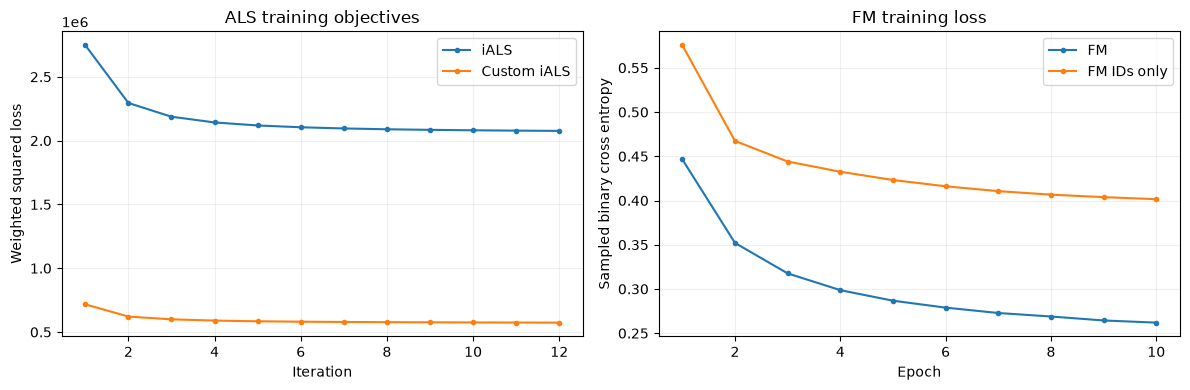

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ['iALS', 'Custom iALS', 'FM', 'FM IDs only']:
    row = max((r for r in validation.to_dict('records') if r['model'] == name), key=lambda r: r['NDCG@10'])
    history = row.get('loss_history')
    if isinstance(history, list):
        ax = axes[0] if 'iALS' in name else axes[1]
        ax.plot(np.arange(1, len(history)+1), history, marker='.', label=name)
axes[0].set(title='ALS training objectives', xlabel='Iteration', ylabel='Weighted squared loss')
axes[1].set(title='FM training loss', xlabel='Epoch', ylabel='Sampled binary cross entropy')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 5. Результаты на test

Выбранные модели обучены на train+validation. Оценки из test используются только
для расчёта метрик. В таблицу включены пять моделей из задания и FM без метаданных.

In [10]:
test = run_final(bundle, selected)
assert test.users.nunique() == 1
columns = ['model', 'NDCG@10', 'MAP@10', 'Recall@10', 'users', 'fit_seconds', 'params']
display(test[columns].sort_values('NDCG@10', ascending=False).reset_index(drop=True))

,model,NDCG@10,MAP@10,Recall@10,users,fit_seconds,params
0,FM IDs only,0.045518,0.030166,0.078532,2224,16.420463,"{'factors': 32, 'epochs': 10, 'lr': 0.003, 'metadata': False}"
1,EASE,0.038123,0.023927,0.065991,2224,17.954249,{'reg': 100}
2,iALS,0.036530,0.022466,0.063987,2224,22.750297,"{'factors': 64, 'reg': 10.0, 'alpha': 20, 'iterations': 12}"
3,ItemKNN,0.031987,0.020602,0.053024,2224,0.936921,"{'neighbors': 100, 'shrinkage': 10}"
4,Custom iALS,0.028243,0.018043,0.048288,2224,22.489078,"{'factors': 64, 'reg': 10.0, 'alpha': 20, 'iterations': 12, 'beta': 0.5}"
5,FM,0.025376,0.015289,0.043880,2224,31.769305,"{'factors': 32, 'epochs': 10, 'lr': 0.003, 'metadata': True}"


### 5.1. Сравнение с популярностью

Дополнительно проверен простой ориентир: товары упорядочиваются по числу отзывов
в доступной обучающей истории. Уже известные пользователю товары исключаются.
Для validation используются частоты из train, для test — из train+validation.
Пользователи, кандидаты и критерий релевантности совпадают с основным экспериментом.
Метод не имеет подбираемых параметров.

Это диагностическое сравнение добавлено после основного эксперимента.
Оно не использовалось для изменения настроек пяти моделей.

,model,NDCG@10,MAP@10,Recall@10,users
period,,,,,
validation,Popularity,0.012639,0.008943,0.016133,3007
test,Popularity,0.047578,0.033066,0.078972,2224


,model,NDCG@10,MAP@10,Recall@10
0,Popularity,0.047578,0.033066,0.078972
1,FM IDs only,0.045518,0.030166,0.078532
2,EASE,0.038123,0.023927,0.065991
3,iALS,0.036530,0.022466,0.063987
4,ItemKNN,0.031987,0.020602,0.053024
5,Custom iALS,0.028243,0.018043,0.048288
6,FM,0.025376,0.015289,0.043880


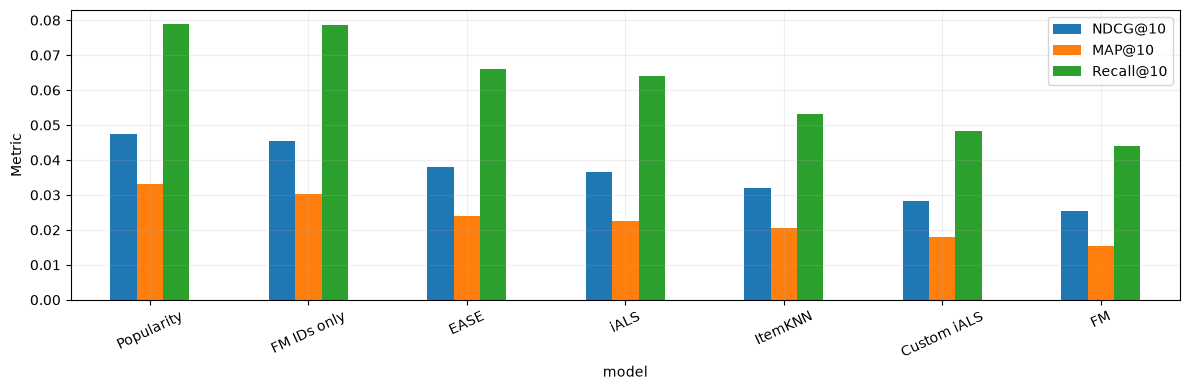

In [11]:
class Popularity:
    def __init__(self, history):
        self.item_counts = np.asarray(history.sum(axis=0)).ravel()

    def score(self, user_ids):
        return np.broadcast_to(self.item_counts, (len(user_ids), len(self.item_counts)))

popularity_rows = []
for period, frame in [('validation', train_frame), ('test', final_frame)]:
    history = make_matrix(frame, bundle['shape'])
    metrics, _ = evaluate(Popularity(history), history, bundle[period], bundle['eligible_users'])
    popularity_rows.append({'period': period, 'model': 'Popularity', **metrics})
popularity_results = pd.DataFrame(popularity_rows)
display(popularity_results.set_index('period'))

metric_columns = ['NDCG@10', 'MAP@10', 'Recall@10']
popularity_test = popularity_results.loc[popularity_results.period == 'test'].iloc[0]
test_comparison = pd.concat([
    test[['model'] + metric_columns],
    pd.DataFrame([popularity_test[['model'] + metric_columns].to_dict()]),
], ignore_index=True).sort_values('NDCG@10', ascending=False)
display(test_comparison.reset_index(drop=True))
test_comparison.set_index('model')[metric_columns].plot.bar(rot=25, figsize=(12, 4))
plt.ylabel('Metric'); plt.tight_layout(); plt.show()

## 6. Выводы

In [12]:
main = test[test.model != 'FM IDs only'].sort_values('NDCG@10', ascending=False)
winner = main.iloc[0]
display(Markdown(f"Среди пяти моделей задания лучший результат у {winner['model']}: "
                 f"NDCG@10 = {winner['NDCG@10']:.6f}. "
                 "Параметры выбраны на validation."))
indexed = test.set_index('model')
control = indexed.loc['FM IDs only']
display(Markdown(f"У FM без метаданных NDCG@10 = {control['NDCG@10']:.6f}. "
                 "Этот вариант добавлен для сравнения с FM с метаданными."))
for left, right, label in [('Custom iALS', 'iALS', 'Изменённый таргет'), ('FM', 'FM IDs only', 'Метаданные FM')]:
    delta = indexed.loc[left, 'NDCG@10'] - indexed.loc[right, 'NDCG@10']
    display(Markdown(f"{label}: разница NDCG@10 {delta:+.6f} относительно {right}. "
                     "Параметры обоих вариантов выбраны на validation."))
# Сравнение таргетов при одинаковых параметрах на validation.
paired = []
for baseline in validation[validation.model == 'iALS'].to_dict('records'):
    matches = [r for r in validation[validation.model == 'Custom iALS'].to_dict('records')
               if {k:v for k,v in r['params'].items() if k != 'beta'} == baseline['params']]
    if matches:
        custom = matches[0]
        paired.append({'params': baseline['params'], 'iALS NDCG@10': baseline['NDCG@10'],
                       'Custom NDCG@10': custom['NDCG@10'],
                       'delta': custom['NDCG@10'] - baseline['NDCG@10']})
display(pd.DataFrame(paired))
popularity_ndcg = float(popularity_test['NDCG@10'])
display(Markdown(f"Популярностный ориентир получил NDCG@10 = {popularity_ndcg:.6f}. "
                 "В этом запуске он выше всех обученных моделей. "
                 "Преимущество персональных моделей над популярностью на test не показано."))


Среди пяти моделей задания лучший результат у EASE: NDCG@10 = 0.038123. Параметры выбраны на validation.

У FM без метаданных NDCG@10 = 0.045518. Этот вариант добавлен для сравнения с FM с метаданными.

Изменённый таргет: разница NDCG@10 -0.008287 относительно iALS. Параметры обоих вариантов выбраны на validation.

Метаданные FM: разница NDCG@10 -0.020142 относительно FM IDs only. Параметры обоих вариантов выбраны на validation.

,params,iALS NDCG@10,Custom NDCG@10,delta
0,"{'factors': 32, 'reg': 1.0, 'alpha': 20, 'iterations': 12}",0.032018,0.021029,-0.010989
1,"{'factors': 32, 'reg': 10.0, 'alpha': 20, 'iterations': 12}",0.031601,0.021490,-0.010111
2,"{'factors': 64, 'reg': 10.0, 'alpha': 20, 'iterations': 12}",0.033474,0.025440,-0.008034


Популярностный ориентир получил NDCG@10 = 0.047578. В этом запуске он выше всех обученных моделей. Преимущество персональных моделей над популярностью на test не показано.

### Интерпретация результатов

NDCG оценивает порядок релевантных товаров. Значение 0,038 не означает точность 3,8%.

Разреженная матрица, короткие истории и большой каталог затрудняют ранжирование.
Однако эти свойства не объясняют автоматически отставание моделей от популярности:
ориентир проверен на тех же пользователях и кандидатах.

EASE имеет наибольший NDCG среди пяти моделей задания, но его отрыв от iALS невелик.
FM без метаданных уступает варианту с метаданными на validation и превосходит его на test.
Периоды, состав пользователей и объём обучающей истории различаются, поэтому
по одному запуску нельзя установить причину смены порядка моделей.

Возможные направления проверки — более широкая сетка параметров, больше эпох FM,
повторные обучения с разными seed и анализ результатов по группам пользователей.
Это гипотезы для следующих экспериментов. Представленные числа их не подтверждают.
Новые настройки следует выбирать на validation; текущие test-результаты не являются
основанием для выбора гиперпараметров.

### Ограничения

Метрики относятся к пользователям и товарам, оставшимся после фильтрации;
большая доля исходного test не оценивается. Исходный 5-core также смещён к активной аудитории.
У бренда и категорий нет исторических версий, их неизменность предполагается.
Отсутствие отзыва при обучении FM используется как негативный пример, хотя пользователь
мог не видеть товар. Размер сетки небольшой, разброс по seed не проверялся.

Версии библиотек и seed указаны ниже. Контрольные суммы архивов сохранены в
`results/data_audit.json`. Проверки формул: `python -m unittest discover -s tests -v`.

In [13]:
environment_path = ROOT / 'results' / 'environment.json'
display(json.loads(environment_path.read_text(encoding='utf-8')) if environment_path.exists()
        else {'python': __import__('sys').version, 'seed': 42})

{'python': '3.13.14',
 'platform': 'Windows-11-10.0.26200-SP0',
 'logical_cpus': 12,
 'torch_cuda': False,
 'versions': {'numpy': '2.5.4',
  'scipy': '1.18.1',
  'pandas': '3.0.6',
  'torch': '2.14.1',
  'matplotlib': '3.11.2',
  'threadpoolctl': '3.7.0'},
 'seed': 42}